<table width="100%" style="border:none; border-collapse:collapse;">
<tr style="border:none;">
<td width="150" style="border:none;"></td>
<td align="center" style="border:none;">
    <h1>Tarea Semanal 8</h1>
    <h2>Teoria de los Circuitos II - R4052</h2>
    <h3>Fabian Alexander Iturrizaga Meza</h3>
    <br>
    <b>Docentes</b><br>
    Profesor: Mariano Llamedo Soria<br>
    Jefe de TPs: Cesar Fuoco<br>
    Ayudante de TPs: David Moharos
</td>
<td width="150" align="right" style="border:none; vertical-align:top;"><img src="./img/logo_UTN.svg" width="150" /></td>
</tr>
</table>

***

## Informe de la tarea semanal

Este notebook contiene la consigna y los desarrollos de la Tarea Semanal 8.

## Consigna

<div align="center"><img src="./img/consigna_ts8.png" alt="Consigna de la Tarea Semanal 8" width="700"/></div>

## Punto 1

### Resolucion manuscrita

#### Version incorrecta

En un principio tomamos la expresion del enunciado de la TS8, la cual los polos CC presentan una omega = 5.
En la resolucion manuscrita dan números reales pero algo extravagantes, luego en la resolución con pytc2 en cierto punto nos da que la función Y no es FRP.
Mas adelante en las simulaciones que realizamos con un número racional bien definido, veremos que la causa del "No FRP" en pytc2 era por error númerico, y que el resultado en papel si esta bien y es realizable.

<div align="center"><img src="./img/punto1_mal_1.jpg" alt="Punto 1, version incorrecta, hoja 1" width="700"/></div>

<div align="center"><img src="./img/punto1_mal_2.jpg" alt="Punto 1, version incorrecta, hoja 2" width="700"/></div>

<div align="center"><img src="./img/punto1_mal_3.jpg" alt="Punto 1, version incorrecta, hoja 3" width="700"/></div>

<div align="center"><img src="./img/punto1_mal_4.jpg" alt="Punto 1, version incorrecta, hoja 4" width="700"/></div>

<div align="center"><img src="./img/puto1_mal_5.jpg" alt="Punto 1, version incorrecta, hoja 5" width="700"/></div>

#### ¿Por que esta mal?

En cierta parte de la resolucion con pytc2 la Y o Z resultante deja de ser FRP y esto deja de ser realizable, en el papel no notamos esa diferencia, asi que haremos varias pruebas.

**Nota numerica:** El resultado "No" de `isFRP(Z8_mal)` (en la simulación que se ve en las siguientes celdas) probablemente se produce al usar `4.4775` como `float`. Se debe a residuos de precision de coma flotante; al modelar `4.4775` como racional exacto, `Z8_mal` resulta FRP.

In [68]:
import sympy as sp
import numpy as np
from IPython.display import display, Markdown
from schemdraw import Drawing

from pytc2.remociones import remover_polo_dc, remover_polo_infinito, isFRP
from pytc2.remociones import remover_valor_en_dc, remover_valor_en_infinito, remover_polo_sigma
from pytc2.sintesis_dipolo import cauer_RC, foster, foster_zRC2yRC
from pytc2.dibujar import (
    dibujar_cauer_RC_RL,
    dibujar_foster_derivacion,
    dibujar_foster_serie,
    dibujar_cierre,
    dibujar_puerto_entrada,
    dibujar_funcion_exc_abajo,
    dibujar_elemento_serie,
    dibujar_elemento_derivacion,
    dibujar_tanque_derivacion,
    dibujar_tanque_RC_serie,
    dibujar_espacio_derivacion,
)
from pytc2.general import print_latex, print_subtitle, a_equal_b_latex_s, s


def mostrar_funcion(nombre, expresion):
    print_latex(a_equal_b_latex_s(nombre, sp.N(expresion, 5)))


def mostrar_componente(nombre, valor, unidad):
    print_latex(a_equal_b_latex_s(nombre, sp.N(sp.simplify(valor), 4)))
    print(f'Unidad: {unidad}')


print_subtitle('Punto 1: funcion objetivo de la version incorrecta')
ZZ_mal = (s**2 + 1*s + 1) / (s**2 + 4.4775*s + 25) / (s + 1)
mostrar_funcion('Z_{RLC,mal}(s)', ZZ_mal)
mostrar_funcion('Y_{RLC,mal}(s)', 1 / ZZ_mal)

Y2_mal, Yc1_mal = remover_polo_infinito(1 / ZZ_mal)
C1_mal = Yc1_mal / s
print_subtitle('Remocion en infinito: extraccion de C1')
mostrar_funcion('Y_{2,mal}(s)', Y2_mal)
mostrar_funcion('Y_{C_1,mal}(s)', Yc1_mal)
mostrar_componente('C_{1,mal}', C1_mal, 'F')

#### Punto 1: funcion objetivo de la version incorrecta

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Remocion en infinito: extraccion de C1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: F


In [69]:
Ginf_mal = sp.limit(Y2_mal, s, sp.oo)
G0_mal = sp.limit(Y2_mal, s, 0)
R1_mal = sp.simplify(1 / np.min((Ginf_mal, G0_mal)))
Y4_mal = sp.factor(Y2_mal - 1 / R1_mal)

print_subtitle('Remocion de la menor conductancia: extraccion de R1')
mostrar_componente('G_{infinito,mal}', Ginf_mal, 'S')
mostrar_componente('G_{0,mal}', G0_mal, 'S')
mostrar_componente('R_{1,mal}', R1_mal, 'ohm')
mostrar_funcion('Y_{4,mal}(s)', Y4_mal)
print('Y4_mal es FRP:', isFRP(Y4_mal))

Z6_mal, Zl1_mal = remover_polo_infinito(1 / Y4_mal)
L1_mal = sp.simplify(Zl1_mal / s)
print_subtitle('Remocion en infinito de Z(s): extraccion de L1')
mostrar_funcion('Z_{6,mal}(s)', Z6_mal)
mostrar_funcion('Z_{L_1,mal}(s)', Zl1_mal)
mostrar_componente('L_{1,mal}', L1_mal, 'H')

#### Remocion de la menor conductancia: extraccion de R1

<IPython.core.display.Math object>

Unidad: S


<IPython.core.display.Math object>

Unidad: S


...

#### Remocion en infinito de Z(s): extraccion de L1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


In [70]:
Rinf_mal = sp.limit(Z6_mal, s, sp.oo)
R0_mal = sp.limit(Z6_mal, s, 0)

print('Rinf_mal =', round(Rinf_mal, 4))
print('R0_mal =', round(R0_mal, 4))

R2_mal = np.min((Rinf_mal, R0_mal))
Z8_mal = sp.factor(sp.simplify(sp.expand(Z6_mal - R2_mal)))

print_subtitle('Remocion de la menor resistencia: extraccion de R2')
mostrar_funcion('Z_{8,mal}(s)', Z8_mal)
frp_Z8_mal = isFRP(Z8_mal)
print('Z8_mal es FRP:', 'Si' if frp_Z8_mal else 'No')

if frp_Z8_mal:
    Y10_mal, Yc2_mal = remover_polo_infinito(1 / Z8_mal)
    C2_mal = Yc2_mal / s
    R3_mal = 1 / Y10_mal
    print_subtitle('Remocion en infinito: extraccion de C2 y R3')
    mostrar_funcion('Y_{10,mal}(s)', Y10_mal)
    mostrar_funcion('Y_{C_2,mal}(s)', Yc2_mal)
    mostrar_componente('C_{2,mal}', C2_mal, 'F')
    mostrar_componente('R_{3,mal}', R3_mal, 'ohm')
else:
    print('No se continua la sintesis: el remanente Z8_mal no es FRP.')

Rinf_mal = 390624999999998.7793
R0_mal = 0.0487


#### Remocion de la menor resistencia: extraccion de R2

<IPython.core.display.Math object>

Z8_mal es FRP: No
No se continua la sintesis: el remanente Z8_mal no es FRP.


In [71]:
if frp_Z8_mal:
    print_subtitle('Componentes obtenidos para la version incorrecta')
    for nombre, valor, unidad in [
        ('C1_mal', C1_mal, 'F'),
        ('R1_mal', R1_mal, 'ohm'),
        ('L1_mal', L1_mal, 'H'),
        ('R2_mal', R2_mal, 'ohm'),
        ('C2_mal', C2_mal, 'F'),
        ('R3_mal', R3_mal, 'ohm'),
    ]:
        mostrar_componente(nombre, valor, unidad)

    Z_red_mal = 1 / (
        s*C1_mal + 1/R1_mal + 1/(s*L1_mal + R2_mal + 1/(s*C2_mal + 1/R3_mal))
    )
    diferencia_Z_mal = sp.factor(sp.cancel(ZZ_mal - Z_red_mal))
    mostrar_funcion('Z_{red,mal}(s)', Z_red_mal)
    mostrar_funcion('Z_{RLC,mal}(s)-Z_{red,mal}(s)', diferencia_Z_mal)
    assert diferencia_Z_mal == 0

    print_subtitle('Circuito sintetizado para la version incorrecta')
    d_mal = dibujar_puerto_entrada(
        Drawing(unit=4),
        voltage_lbl=('+', '$V$', '-'),
        current_lbl='$I$',
    )
    d_mal = dibujar_funcion_exc_abajo(d_mal, 'Z', ZZ_mal, hacia_salida=True, k_gap_width=0.5)
    d_mal = dibujar_elemento_derivacion(d_mal, 'C', C1_mal)
    d_mal = dibujar_espacio_derivacion(d_mal)
    d_mal = dibujar_elemento_derivacion(d_mal, 'R', R1_mal)
    d_mal = dibujar_elemento_serie(d_mal, 'L', L1_mal)
    d_mal = dibujar_elemento_serie(d_mal, 'R', R2_mal)
    d_mal = dibujar_elemento_derivacion(d_mal, 'C', C2_mal)
    d_mal = dibujar_espacio_derivacion(d_mal)
    d_mal = dibujar_elemento_derivacion(d_mal, 'R', R3_mal)
    display(d_mal)
else:
    print_subtitle('No hay realizacion para la version incorrecta')
    print('La sintesis se detiene porque Z8_mal no es FRP.')

#### No hay realizacion para la version incorrecta

La sintesis se detiene porque Z8_mal no es FRP.


### Comprobacion con el coeficiente racional exacto

Se repite la sintesis de la misma impedancia, representando `4.4775` como un racional exacto. Asi se evita introducir residuos de redondeo en las remociones.

In [76]:
print_subtitle('Punto 1: funcion objetivo con coeficiente racional exacto')
ZZ_mal_racional = (s**2 + s + 1) / (s**2 + sp.Rational('4.4775')*s + 25) / (s + 1)
mostrar_funcion('Z_{RLC,racional}(s)', ZZ_mal_racional)
mostrar_funcion('Y_{RLC,racional}(s)', 1 / ZZ_mal_racional)

Y2_mal_racional, Yc1_mal_racional = remover_polo_infinito(1 / ZZ_mal_racional)
C1_mal_racional = sp.simplify(Yc1_mal_racional / s)
print_subtitle('Remocion en infinito: extraccion de C1')
mostrar_funcion('Y_{2,racional}(s)', Y2_mal_racional)
mostrar_funcion('Y_{C_1,racional}(s)', Yc1_mal_racional)
mostrar_componente('C_{1,racional}', C1_mal_racional, 'F')

#### Punto 1: funcion objetivo con coeficiente racional exacto

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Remocion en infinito: extraccion de C1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: F


In [77]:
Ginf_mal_racional = sp.limit(Y2_mal_racional, s, sp.oo)
G0_mal_racional = sp.limit(Y2_mal_racional, s, 0)
R1_mal_racional = sp.simplify(1 / np.min((Ginf_mal_racional, G0_mal_racional)))
Y4_mal_racional = sp.factor(
    sp.simplify(sp.expand(Y2_mal_racional - 1 / R1_mal_racional))
)

print_subtitle('Remocion de la menor admitancia: extraccion de R1')
mostrar_componente('G_{infinito,racional}', Ginf_mal_racional, 'S')
mostrar_componente('G_{0,racional}', G0_mal_racional, 'S')
mostrar_componente('R_{1,racional}', R1_mal_racional, 'ohm')
mostrar_funcion('Y_{4,racional}(s)', Y4_mal_racional)
print('Y4_racional es FRP:', isFRP(Y4_mal_racional))

Z6_mal_racional, Zl1_mal_racional = remover_polo_infinito(1 / Y4_mal_racional)
L1_mal_racional = sp.simplify(Zl1_mal_racional / s)
print_subtitle('Remocion en infinito de Z(s): extraccion de L1')
mostrar_funcion('Z_{6,racional}(s)', Z6_mal_racional)
mostrar_componente('L_{1,racional}', L1_mal_racional, 'H')
print('Z6_racional es FRP:', isFRP(Z6_mal_racional))

#### Remocion de la menor admitancia: extraccion de R1

<IPython.core.display.Math object>

Unidad: S


<IPython.core.display.Math object>

Unidad: S


...

Y4_racional es FRP: True


#### Remocion en infinito de Z(s): extraccion de L1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H
Z6_racional es FRP: True


In [78]:
Rinf_mal_racional = sp.limit(Z6_mal_racional, s, sp.oo)
R0_mal_racional = sp.limit(Z6_mal_racional, s, 0)
R2_mal_racional = sp.simplify(np.min((Rinf_mal_racional, R0_mal_racional)))
Z8_mal_racional = sp.factor(
    sp.simplify(sp.expand(Z6_mal_racional - R2_mal_racional))
)

print_subtitle('Remocion de la menor resistencia: extraccion de R2')
mostrar_componente('R_{infinito,racional}', Rinf_mal_racional, 'ohm')
mostrar_componente('R_{0,racional}', R0_mal_racional, 'ohm')
mostrar_componente('R_{2,racional}', R2_mal_racional, 'ohm')
mostrar_funcion('Z_{8,racional}(s)', Z8_mal_racional)
frp_Z8_mal_racional = isFRP(Z8_mal_racional)
print('Z8_racional es FRP:', frp_Z8_mal_racional)

if frp_Z8_mal_racional:
    Y10_mal_racional, Yc2_mal_racional = remover_polo_infinito(1 / Z8_mal_racional)
    C2_mal_racional = sp.simplify(Yc2_mal_racional / s)
    R3_mal_racional = sp.simplify(1 / Y10_mal_racional)
    print_subtitle('Remocion en infinito: extraccion de C2 y R3')
    mostrar_funcion('Y_{10,racional}(s)', Y10_mal_racional)
    mostrar_funcion('Y_{C_2,racional}(s)', Yc2_mal_racional)
    mostrar_componente('C_{2,racional}', C2_mal_racional, 'F')
    mostrar_componente('R_{3,racional}', R3_mal_racional, 'ohm')
else:
    print('No se continua la sintesis: Z8_racional no es FRP.')

#### Remocion de la menor resistencia: extraccion de R2

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

Unidad: ohm


...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: F


<IPython.core.display.Math object>

Unidad: ohm


#### Componentes obtenidos con coeficiente racional exacto

<IPython.core.display.Math object>

Unidad: F


<IPython.core.display.Math object>

Unidad: ohm


...

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Circuito sintetizado con coeficiente racional exacto

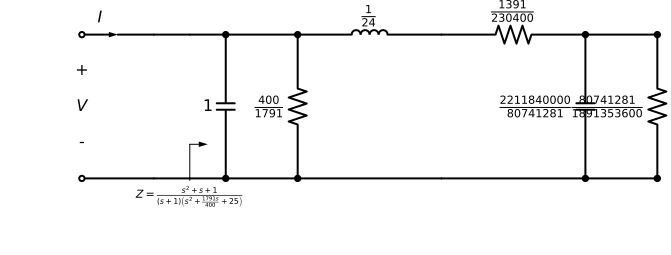

In [79]:
if frp_Z8_mal_racional:
    print_subtitle('Componentes obtenidos con coeficiente racional exacto')
    for nombre, valor, unidad in [
        ('C1_racional', C1_mal_racional, 'F'),
        ('R1_racional', R1_mal_racional, 'ohm'),
        ('L1_racional', L1_mal_racional, 'H'),
        ('R2_racional', R2_mal_racional, 'ohm'),
        ('C2_racional', C2_mal_racional, 'F'),
        ('R3_racional', R3_mal_racional, 'ohm'),
    ]:
        mostrar_componente(nombre, valor, unidad)

    Z_red_mal_racional = 1 / (
        s*C1_mal_racional + 1/R1_mal_racional
        + 1/(s*L1_mal_racional + R2_mal_racional
             + 1/(s*C2_mal_racional + 1/R3_mal_racional))
    )
    diferencia_Z_mal_racional = sp.cancel(ZZ_mal_racional - Z_red_mal_racional)
    mostrar_funcion('Z_{red,racional}(s)', Z_red_mal_racional)
    mostrar_funcion('Z_{RLC,racional}(s)-Z_{red,racional}(s)', diferencia_Z_mal_racional)
    assert diferencia_Z_mal_racional == 0

    print_subtitle('Circuito sintetizado con coeficiente racional exacto')
    d_mal_racional = dibujar_puerto_entrada(
        Drawing(unit=4),
        voltage_lbl=('+', '$V$', '-'),
        current_lbl='$I$',
    )
    d_mal_racional = dibujar_funcion_exc_abajo(
        d_mal_racional, 'Z', ZZ_mal_racional, hacia_salida=True, k_gap_width=0.5
    )
    d_mal_racional = dibujar_elemento_derivacion(d_mal_racional, 'C', C1_mal_racional)
    d_mal_racional = dibujar_espacio_derivacion(d_mal_racional)
    d_mal_racional = dibujar_elemento_derivacion(d_mal_racional, 'R', R1_mal_racional)
    d_mal_racional = dibujar_elemento_serie(d_mal_racional, 'L', L1_mal_racional)
    d_mal_racional = dibujar_elemento_serie(d_mal_racional, 'R', R2_mal_racional)
    d_mal_racional = dibujar_elemento_derivacion(d_mal_racional, 'C', C2_mal_racional)
    d_mal_racional = dibujar_espacio_derivacion(d_mal_racional)
    d_mal_racional = dibujar_elemento_derivacion(d_mal_racional, 'R', R3_mal_racional)
    display(d_mal_racional)
else:
    print('No se puede dibujar la red porque Z8_racional no es FRP.')

### Conclusión

Con `4.4775` representado como `float`, las remociones acumulan residuos de redondeo y `isFRP` puede marcar `Z8` como no FRP. Al usar el racional exacto, `Y4`, `Z6` y `Z8` resultan FRP, todos los componentes extraídos son positivos y la impedancia de la red coincide exactamente con la función objetivo. Por lo tanto, el resultado negativo de la versión con `float` es un artefacto numérico, no una prueba de que la función exacta no sea realizable.

Entonces, el resultado que obtuvimos en papel NO esta mal, agregaremos la nota mas adelante al finalizar el ejercicio.

### Resolucion manuscrita

#### Version "correcta"

Aqui usaremos el enunciado de la guía de ejercicios que da como omega sqrt(5), lo que lleva a un resultado mas amigable

<div align="center"><img src="./img/putno1_bien_1.jpg" alt="Punto 1, version correcta, hoja 1" width="700"/></div>

<div align="center"><img src="./img/punto1_bien_2.jpg" alt="Punto 1, version correcta, hoja 2" width="700"/></div>

<div align="center"><img src="./img/punto1_bien_3.jpg" alt="Punto 1, version correcta, hoja 3" width="700"/></div>

In [72]:
print_subtitle('Punto 1: funcion objetivo de la version correcta')
ZZ_bien = (s**2 + s + 1) / (s**2 + 2*s + 5) / (s + 1)
mostrar_funcion('Z_{RLC,bien}(s)', ZZ_bien)
mostrar_funcion('Y_{RLC,bien}(s)', 1 / ZZ_bien)

Y2_bien, Yc1_bien = remover_polo_infinito(1 / ZZ_bien)
C1_bien = sp.simplify(Yc1_bien / s)
print_subtitle('Remocion en infinito: extraccion de C1')
mostrar_funcion('Y_{2,bien}(s)', Y2_bien)
mostrar_funcion('Y_{C_1,bien}(s)', Yc1_bien)
mostrar_componente('C_{1,bien}', C1_bien, 'F')

#### Punto 1: funcion objetivo de la version correcta

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Remocion en infinito: extraccion de C1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: F


In [80]:
Ginf_bien = sp.limit(Y2_bien, s, sp.oo)
G0_bien = sp.limit(Y2_bien, s, 0)
R1_bien = sp.simplify(1 / np.min((Ginf_bien, G0_bien)))
Y4_bien = sp.factor(Y2_bien - 1 / R1_bien)

print_subtitle('Remocion de la menor conductancia: extraccion de R1')
mostrar_componente('G_{infinito,bien}', Ginf_bien, 'S')
mostrar_componente('G_{0,bien}', G0_bien, 'S')
mostrar_componente('R_{1,bien}', R1_bien, 'ohm')
mostrar_funcion('Y_{4,bien}(s)', Y4_bien)
print('Y4_bien es FRP:', isFRP(Y4_bien))

Z_antes_L1_bien = sp.factor(1 / Y4_bien)
R_DC_bien = sp.limit(Z_antes_L1_bien, s, 0)
Z_sin_R_DC_bien = sp.factor(Z_antes_L1_bien - R_DC_bien)
print_subtitle('Por que no se remueve R2 antes de L1')
print_latex(a_equal_b_latex_s('Z_{antes\ de\ L1}(s)', Z_antes_L1_bien))
print_latex(a_equal_b_latex_s('Z_{DC,bien}', R_DC_bien))
print_latex(a_equal_b_latex_s('Z_{remanente}(s)', Z_sin_R_DC_bien))
print('El remanente despues de remover Z_DC es FRP:', isFRP(Z_sin_R_DC_bien))
display(Markdown(
    '**Orden de remocion:** no conviene remover primero `R2`. En continua, el menor valor de impedancia es '
    '$Z(0)=1/3\\,\\Omega$, que en la topologia final corresponde a $R_2+R_3$. Si se resta ese valor '
    'en esta etapa, se elimina toda la contribucion resistiva de esa rama y el remanente deja de ser FRP. '
    'Por eso se extrae primero $L_1$ mediante la remocion en infinito.'
))

Z6_bien, Zl1_bien = remover_polo_infinito(1 / Y4_bien)
L1_bien = sp.simplify(Zl1_bien / s)
print_subtitle('Remocion en infinito de Z(s): extraccion de L1')
mostrar_funcion('Z_{6,bien}(s)', Z6_bien)
mostrar_funcion('Z_{L_1,bien}(s)', Zl1_bien)
mostrar_componente('L_{1,bien}', L1_bien, 'H')

#### Remocion de la menor conductancia: extraccion de R1

<IPython.core.display.Math object>

Unidad: S


<IPython.core.display.Math object>

Unidad: S


...

#### Remocion en infinito de Z(s): extraccion de L1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


In [74]:
Rinf_bien = sp.limit(Z6_bien, s, sp.oo)
R0_bien = sp.limit(Z6_bien, s, 0)
R2_bien = sp.simplify(np.min((Rinf_bien, R0_bien)))
Z8_bien = sp.factor(Z6_bien - R2_bien)

print_subtitle('Remocion de la menor resistencia: extraccion de R2')
mostrar_componente('R_{infinito,bien}', Rinf_bien, 'ohm')
mostrar_componente('R_{0,bien}', R0_bien, 'ohm')
mostrar_componente('R_{2,bien}', R2_bien, 'ohm')
mostrar_funcion('Z_{8,bien}(s)', Z8_bien)
print('Z8_bien es FRP:', isFRP(Z8_bien))

Y10_bien, Yc2_bien = remover_polo_infinito(1 / Z8_bien)
C2_bien = sp.simplify(Yc2_bien / s)
R3_bien = sp.simplify(1 / Y10_bien)
print_subtitle('Remocion en infinito: extraccion de C2 y R3')
mostrar_funcion('Y_{10,bien}(s)', Y10_bien)
mostrar_funcion('Y_{C_2,bien}(s)', Yc2_bien)
mostrar_componente('C_{2,bien}', C2_bien, 'F')
mostrar_componente('R_{3,bien}', R3_bien, 'ohm')

#### Remocion de la menor resistencia: extraccion de R2

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

Unidad: ohm


...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: F


<IPython.core.display.Math object>

Unidad: ohm


#### Componentes obtenidos para la version correcta

<IPython.core.display.Math object>

Unidad: F


<IPython.core.display.Math object>

Unidad: ohm


...

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Circuito sintetizado para la version correcta

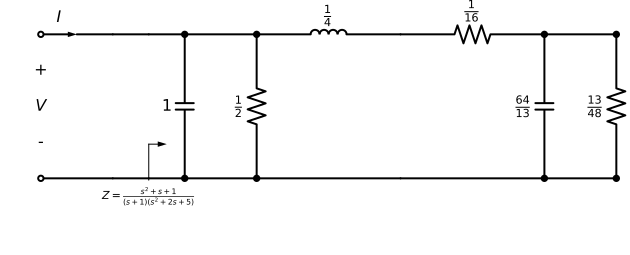

In [75]:
print_subtitle('Componentes obtenidos para la version correcta')
for nombre, valor, unidad in [
    ('C1_bien', C1_bien, 'F'),
    ('R1_bien', R1_bien, 'ohm'),
    ('L1_bien', L1_bien, 'H'),
    ('R2_bien', R2_bien, 'ohm'),
    ('C2_bien', C2_bien, 'F'),
    ('R3_bien', R3_bien, 'ohm'),
]:
    mostrar_componente(nombre, valor, unidad)

Z_red_bien = 1 / (
    s*C1_bien + 1/R1_bien + 1/(s*L1_bien + R2_bien + 1/(s*C2_bien + 1/R3_bien))
)
diferencia_Z_bien = sp.factor(sp.cancel(ZZ_bien - Z_red_bien))
mostrar_funcion('Z_{red,bien}(s)', Z_red_bien)
mostrar_funcion('Z_{RLC,bien}(s)-Z_{red,bien}(s)', diferencia_Z_bien)
assert diferencia_Z_bien == 0

print_subtitle('Circuito sintetizado para la version correcta')
d_bien = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', '$V$', '-'),
    current_lbl='$I$',
)
d_bien = dibujar_funcion_exc_abajo(d_bien, 'Z', ZZ_bien, hacia_salida=True, k_gap_width=0.5)
d_bien = dibujar_elemento_derivacion(d_bien, 'C', C1_bien)
d_bien = dibujar_espacio_derivacion(d_bien)
d_bien = dibujar_elemento_derivacion(d_bien, 'R', R1_bien)
d_bien = dibujar_elemento_serie(d_bien, 'L', L1_bien)
d_bien = dibujar_elemento_serie(d_bien, 'R', R2_bien)
d_bien = dibujar_elemento_derivacion(d_bien, 'C', C2_bien)
d_bien = dibujar_espacio_derivacion(d_bien)
d_bien = dibujar_elemento_derivacion(d_bien, 'R', R3_bien)
display(d_bien)

### Nota sobre la interpretación del punto 1

En retrospectiva, llamar incorrecta a la primera solución que planetamos del Z con omega = 5 en sus polos no era del todo adecuado. El resultado inicial hizo pensar que podía haber un problema en el enunciado, pero la diferencia surgía de representar `4.4775` como `float`. Al usar el coeficiente racional exacto, la función resulta FRP y la síntesis se verifica, aunque con números muy complicados.

Entonces AMBAS soluciones estan bien, solamente son problemas distintos

### Simulacion en LTspice (Version "correcta")

#### Circuito implementado

<div align="center"><img src="./img/punto1_circuito.png" alt="Circuito de la version correcta del punto 1 en LTspice" width="850"/></div>

#### Cursor a baja frecuencia

<div align="center"><img src="./img/punto1_simulacion1.png" alt="Respuesta de impedancia con cursor a baja frecuencia" width="100%"/></div>

El cursor a **1.03948 mHz** mide **200.352809 mOhm** y una fase de **-149.4914 mdeg** (aprox. **-0.1495 deg**). Esto concuerda con el límite en continua, $Z(0)=0.2\,\Omega$, y con una fase que tiende a $0^\circ$.

#### Cursor a alta frecuencia

<div align="center"><img src="./img/punto1_simulacion2.png" alt="Respuesta de impedancia con cursor a 100 Hz" width="100%"/></div>

A **100 Hz**, el cursor mide **1.5915575 mOhm** y **-89.81762 deg**. En alta frecuencia, $Z(s)\approx 1/s$, por lo que $|Z(j2\pi f)|\approx 1/(2\pi f)$ y la fase tiende a $-90^\circ$. Para 100 Hz se esperan aproximadamente **1.59155 mOhm**, en acuerdo con la simulacion.

## Punto 2

### Resolucion manuscrita

<div align="center"><img src="./img/punto2_1.jpg" alt="Punto 2, resolucion manuscrita, hoja 1" width="700"/></div>

<div align="center"><img src="./img/punto2_2.jpg" alt="Punto 2, resolucion manuscrita, hoja 2" width="700"/></div>

<div align="center"><img src="./img/punto2_3.jpg" alt="Punto 2, resolucion manuscrita, hoja 3" width="700"/></div>

<div align="center"><img src="./img/punto2_4.jpg" alt="Punto 2, resolucion manuscrita, hoja 4" width="700"/></div>

<div align="center"><img src="./img/punto2_5.jpg" alt="Punto 2, resolucion manuscrita, hoja 5" width="700"/></div>

### Resolucion simbolica por remociones parciales

Se parte de la impedancia

$$Z(s)=\frac{s^2+6s+8}{s^2+4s+3}$$

Las constantes de tiempo fijan los polos de los tanques RC: $\sigma_1=-1/(R_1C_1)=-5$ y $\sigma_2=-1/(R_2C_2)=-4$.

Primero se hace una remocion parcial sobre $Z(s)$ para desplazar el cero ubicado en $s=-4$ hasta $s=-5$. Luego se pasa a admitancia y se remueve el polo en $-5$, extrayendo el primer tanque RC. La admitancia remanente tiene un polo en $s=-11/5=-2.2$; al invertirla, ese polo se convierte en un cero de la impedancia. Se hace entonces una segunda remocion parcial en impedancia para ubicar un cero en $s=-4$, y se vuelve a admitancia para extraer el segundo tanque. La admitancia remanente final corresponde a la resistencia de terminacion.

In [81]:
print_subtitle('Punto 2: primera remocion parcial en impedancia')
Z_p2 = (s**2 + 6*s + 8) / (s**2 + 4*s + 3)
mostrar_funcion('Z(s)', Z_p2)

# Se desplaza el cero original en -4 hasta sigma_1 = -5.
Z2_p2, Z1_p2 = remover_valor_en_dc(Z_p2, sigma_zero=-5)
print_subtitle('Remocion parcial para ubicar el cero en -5')
mostrar_componente('Z_1', Z1_p2, 'ohm')
mostrar_funcion('Z_2(s)', Z2_p2)
print('Z2_p2 es FRP:', isFRP(Z2_p2))
assert sp.simplify(Z2_p2.subs(s, -5)) == 0

#### Punto 2: primera remocion parcial en impedancia

<IPython.core.display.Math object>

#### Remocion parcial para ubicar el cero en -5

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

Z2_p2 es FRP: True


In [82]:
Y2_p2 = sp.factor(1 / Z2_p2)
Y4_p2, YR1C1_p2, R1_p2, C1_p2 = remover_polo_sigma(
    Y2_p2,
    sigma=-5,
    isImpedance=False,
    isRC=True,
)

print_subtitle('Remocion del primer tanque RC en admitancia')
mostrar_funcion('Y_2(s)', Y2_p2)
mostrar_funcion('Y_{R_1C_1}(s)', YR1C1_p2)
mostrar_componente('R_1', R1_p2, 'ohm')
mostrar_componente('C_1', C1_p2, 'F')
mostrar_componente('R_1 C_1', sp.simplify(R1_p2*C1_p2), 's')
mostrar_funcion('Y_4(s)', Y4_p2)
print('Y4_p2 es FRP:', isFRP(Y4_p2))
assert sp.simplify(R1_p2*C1_p2 - sp.Rational(1, 5)) == 0
assert sp.solve(sp.denom(Y4_p2), s) == [-sp.Rational(11, 5)]

#### Remocion del primer tanque RC en admitancia

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: ohm


...

Unidad: F


<IPython.core.display.Math object>

Unidad: s


<IPython.core.display.Math object>

Y4_p2 es FRP: True


In [83]:
Z4_p2 = sp.factor(1 / Y4_p2)
Z6_p2, Z2_p2 = remover_valor_en_dc(Z4_p2, sigma_zero=-4)
Y6_p2 = sp.factor(1 / Z6_p2)

print_subtitle('Segunda remocion parcial: desplazar el cero hasta -4')
mostrar_funcion('Z_4(s)=1/Y_4(s)', Z4_p2)
mostrar_componente('Z_2', Z2_p2, 'ohm')
mostrar_funcion('Z_6(s)', Z6_p2)
mostrar_funcion('Y_6(s)=1/Z_6(s)', Y6_p2)
print('Z6_p2 es FRP:', isFRP(Z6_p2))
print('Y6_p2 es FRP:', isFRP(Y6_p2))
assert sp.simplify(Z6_p2.subs(s, -4)) == 0

#### Segunda remocion parcial: desplazar el cero hasta -4

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Z6_p2 es FRP: True
Y6_p2 es FRP: True


In [84]:
Y8_p2, YR2C2_p2, R2_p2, C2_p2 = remover_polo_sigma(
    Y6_p2,
    sigma=-4,
    isImpedance=False,
    isRC=True,
)

print_subtitle('Remocion del segundo tanque RC en admitancia')
mostrar_funcion('Y_{R_2C_2}(s)', YR2C2_p2)
mostrar_componente('R_2', R2_p2, 'ohm')
mostrar_componente('C_2', C2_p2, 'F')
mostrar_componente('R_2 C_2', sp.simplify(R2_p2*C2_p2), 's')
mostrar_funcion('Y_8(s)', Y8_p2)
print('Y8_p2 es FRP:', isFRP(Y8_p2))
assert sp.simplify(R2_p2*C2_p2 - sp.Rational(1, 4)) == 0

#### Remocion del segundo tanque RC en admitancia

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

Unidad: F


<IPython.core.display.Math object>

Unidad: s


<IPython.core.display.Math object>

Y8_p2 es FRP: True


#### Resistencia terminal y verificacion de la red

<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

Unidad: ohm


<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Circuito sintetizado por remociones parciales

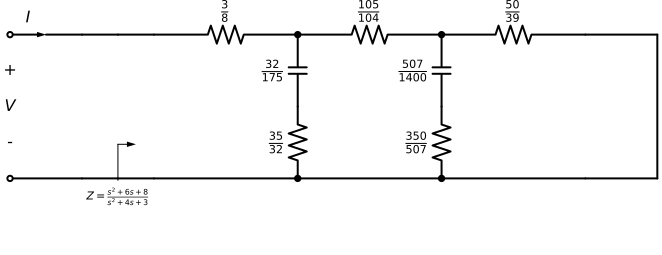

In [86]:
Z3_p2 = sp.factor(1 / Y8_p2)
print_subtitle('Resistencia terminal y verificacion de la red')
mostrar_componente('Z_1', Z1_p2, 'ohm')
mostrar_componente('Z_2', Z2_p2, 'ohm')
mostrar_componente('Z_3', Z3_p2, 'ohm')

Z_red_p2 = sp.factor(
    Z1_p2 + 1 / (YR1C1_p2 + 1 / (Z2_p2 + 1 / (YR2C2_p2 + Y8_p2)))
)
diferencia_Z_p2 = sp.factor(sp.cancel(Z_p2 - Z_red_p2))
mostrar_funcion('Z_{red}(s)', Z_red_p2)
mostrar_funcion('Z(s)-Z_{red}(s)', diferencia_Z_p2)
assert diferencia_Z_p2 == 0

print_subtitle('Circuito sintetizado por remociones parciales')
from pytc2.dibujar import dibujar_tanque_RC_derivacion

d_p2 = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', '$V$', '-'),
    current_lbl='$I$',
)
d_p2 = dibujar_funcion_exc_abajo(d_p2, 'Z', Z_p2, hacia_salida=True, k_gap_width=0.5)
d_p2 = dibujar_elemento_serie(d_p2, 'R', Z1_p2)
d_p2 = dibujar_tanque_RC_derivacion(
    d_p2,
    resistor_label=R1_p2,
    capacitor_lbl=C1_p2,
)
d_p2 = dibujar_elemento_serie(d_p2, 'R', Z2_p2)
d_p2 = dibujar_tanque_RC_derivacion(
    d_p2,
    resistor_label=R2_p2,
    capacitor_lbl=C2_p2,
)
d_p2 = dibujar_elemento_serie(d_p2, 'R', Z3_p2)
d_p2 = dibujar_cierre(d_p2)
display(d_p2)

### Simulacion en LTspice

#### Circuito implementado

<div align="center"><img src="./img/punto2_circuito.png" alt="Circuito del punto 2 implementado en LTspice" width="900"/></div>

#### Cursor a baja frecuencia

<div align="center"><img src="./img/punto2_simulacion1.png" alt="Respuesta de impedancia del punto 2 con cursor a 1 mHz" width="100%"/></div>

A **1 mHz**, el cursor mide **2.6666246 ohm** y una fase de **-209.99575 mdeg** (aprox. **-0.2100 deg**). La magnitud concuerda con el limite en continua: $Z(0)=8/3\,\Omega\approx2.6667\,\Omega$; la pequena fase se debe a estar midiendo a una frecuencia baja pero no nula.

#### Cursor a alta frecuencia

<div align="center"><img src="./img/punto2_simulacion2.png" alt="Respuesta de impedancia del punto 2 con cursor a 100 Hz" width="100%"/></div>

A **100 Hz**, el cursor mide **1.0000127 ohm** y una fase de **-182.37474 mdeg** (aprox. **-0.1824 deg**). Para frecuencias altas, los terminos de mayor orden de numerador y denominador dan $Z(\infty)=1\,\Omega$, en acuerdo con la simulacion.